<a href="https://colab.research.google.com/github/0110225176-png/Machine-Learning/blob/main/TugasPraktikumPekan04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)

In [3]:
from google.colab import drive
drive.mount ('/content/drive')

Mounted at /content/drive


In [27]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Semester03/ML 2026/Praktikum04/data/calonpembelimobil.csv')
df.head()

,ID,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Beli_Mobil
0,1,32,1,0,0,240,1
1,2,49,2,1,1,100,0
2,3,52,1,0,2,250,1
3,4,26,2,1,1,130,0
4,5,45,3,0,2,237,1


In [7]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (1000, 7)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID              1000 non-null   int64
 1   Usia            1000 non-null   int64
 2   Status          1000 non-null   int64
 3   Kelamin         1000 non-null   int64
 4   Memiliki_Mobil  1000 non-null   int64
 5   Penghasilan     1000 non-null   int64
 6   Beli_Mobil      1000 non-null   int64
dtypes: int64(7)
memory usage: 54.8 KB


In [10]:
#cek missing value
print(df.isnull().sum())

ID                0
Usia              0
Status            0
Kelamin           0
Memiliki_Mobil    0
Penghasilan       0
Beli_Mobil        0
dtype: int64


In [8]:
# Pemeriksaan data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


In [11]:
kolom_kategorikal = [
    'Status',
    'Kelamin',
    'Memiliki_Mobil',
    'Beli_Mobil'
]

for kolom in kolom_kategorikal:
    print(kolom, ":", df[kolom].unique())

Status : [1 2 3 0]
Kelamin : [0 1]
Memiliki_Mobil : [0 1 2 4 3]
Beli_Mobil : [1 0]


In [12]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

print("Ukuran data setelah preprocessing:", df_clean.shape)
print(df_clean.isnull().sum())

Ukuran data setelah preprocessing: (1000, 7)
ID                0
Usia              0
Status            0
Kelamin           0
Memiliki_Mobil    0
Penghasilan       0
Beli_Mobil        0
dtype: int64


In [13]:
X = df_clean[
    [
        'Usia',
        'Status',
        'Kelamin',
        'Memiliki_Mobil',
        'Penghasilan'
    ]
]

y = df_clean['Beli_Mobil']

print("Ukuran fitur:", X.shape)
print("Ukuran target:", y.shape)

Ukuran fitur: (1000, 5)
Ukuran target: (1000,)


In [14]:
fitur_numerik = ['Usia', 'Penghasilan']

fitur_kategorikal = [
    'Status',
    'Kelamin',D
    'Memiliki_Mobil'
]

preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), fitur_numerik),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         fitur_kategorikal)
    ]
)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

Data training: (800, 5)
Data testing: (200, 5)


In [16]:
model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    random_state=42
)

clf = Pipeline([
    ('preprocess', preprocess),
    ('model', model)
])

In [17]:
clf.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih.")

Model Logistic Regression berhasil dilatih.


In [18]:
y_pred = clf.predict(X_test)

print("Hasil prediksi:")
print(y_pred)

Hasil prediksi:
[1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0 0 1 1 0 1 1 1 1 1 1 1 0 1 1 0 1 0
 1 1 1 1 0 0 1 1 1 0 0 1 1 0 1 1 1 1 0 0 0 1 0 1 1 1 0 1 0 1 1 1 0 1 1 0 1
 0 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1 0 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 0 1 1
 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 0 0 0 0 0 1 0 1 1 0 1 1 1
 1 1 0 0 0 0 1 1 0 1 0 1 1 1 0 0 1 1 0 0 0 1 0 1 1 1 0 0 1 1 1 0 1 1 1 1 1
 1 1 0 1 1 0 1 1 1 1 1 0 1 1 0]


In [19]:
y_prob = clf.predict_proba(X_test)[:, 1]

print("Probabilitas prediksi:")
print(y_prob)

Probabilitas prediksi:
[0.99332974 0.72242446 0.51100973 0.99979978 0.99975175 0.98296238
 0.99998254 0.0156263  0.30565489 0.04910443 0.00778158 0.99310442
 0.04731861 0.99999555 0.24750018 0.16065944 0.01683494 0.30274675
 0.52564989 0.09961176 0.0122915  0.98790795 0.99709742 0.04652008
 0.99902362 0.98269454 0.99898181 0.75114238 0.80323588 0.74287353
 0.87112574 0.00867218 0.99996605 0.9996401  0.22159833 0.8194273
 0.0201862  0.99991206 0.99998837 0.99554877 0.50318773 0.10353233
 0.09925315 0.99998688 0.98044385 0.99962994 0.13714554 0.0033086
 0.78049041 0.99963767 0.02088684 0.9855593  0.81696291 0.9969395
 0.99889712 0.08542638 0.00383752 0.1630594  0.5396774  0.06903054
 0.99998665 0.99967159 0.95903975 0.00541511 0.99825355 0.30822622
 0.99999708 0.99991708 0.90647828 0.00842094 0.78337012 0.99772155
 0.04783075 0.69034598 0.02361711 0.98741999 0.98385673 0.99432977
 0.99989541 0.51344334 0.90199485 0.99871781 0.99953986 0.03749173
 0.99032404 0.9999625  0.99835815 0.019084

In [20]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.935
Precision: 0.9523809523809523
Recall   : 0.9448818897637795
F1-Score : 0.9486166007905138


Confusion Matrix:
[[ 67   6]
 [  7 120]]


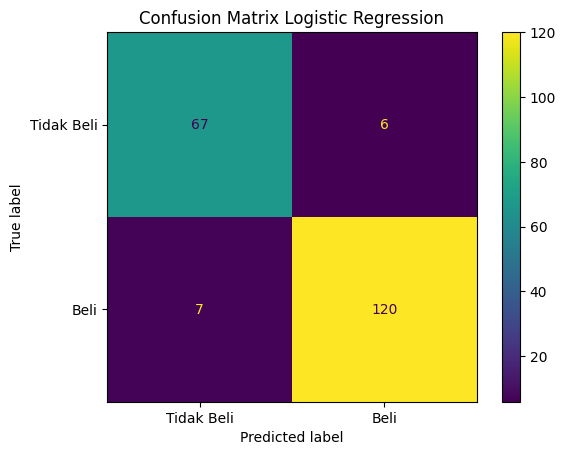

In [21]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Tidak Beli', 'Beli']
).plot(values_format='d')

plt.title('Confusion Matrix Logistic Regression')
plt.show()

In [22]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Tidak Beli', 'Beli'],
    zero_division=0
))

              precision    recall  f1-score   support

  Tidak Beli       0.91      0.92      0.91        73
        Beli       0.95      0.94      0.95       127

    accuracy                           0.94       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.94      0.94      0.94       200



In [23]:
data_baru = pd.DataFrame({
    'Usia': [32, 45],
    'Status': [1, 3],
    'Kelamin': [0, 1],
    'Memiliki_Mobil': [0, 2],
    'Penghasilan': [240, 237]
})

print(data_baru)


   Usia  Status  Kelamin  Memiliki_Mobil  Penghasilan
0    32       1        0               0          240
1    45       3        1               2          237


In [24]:
prediksi_baru = clf.predict(data_baru)

probabilitas_baru = clf.predict_proba(data_baru)[:, 1]

In [25]:
hasil_baru = data_baru.copy()

hasil_baru['Prediksi_Beli_Mobil'] = prediksi_baru

hasil_baru['Probabilitas_Beli'] = probabilitas_baru

display(hasil_baru)

,Usia,Status,Kelamin,Memiliki_Mobil,Penghasilan,Prediksi_Beli_Mobil,Probabilitas_Beli
0,32,1,0,0,240,1,0.850266
1,45,3,1,2,237,1,0.635450
